# Lab 04: Random Forest Ensemble — Credit Default Risk Classification

This laboratory project explores ensemble learning using Random Forests (`RandomForestClassifier`) to predict loan default risk based on applicant financial profiles.

### Objectives:
1. Ingest loan applicant financial indicators.
2. Exploratory Data Analysis (EDA) and class balance inspection.
3. Compare a baseline Single Decision Tree vs. Random Forest Ensemble.
4. Evaluate Out-of-Bag (OOB) generalization error.
5. Hyperparameter analysis: impact of ensemble size (`n_estimators`) on variance.
6. Gini feature importance ranking and visualization.
7. Decision thresholding and inference on unseen applicant profiles.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

# Load dataset
df = pd.read_csv("data.csv")
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset Shape: (500, 7)

First 5 rows:


,credit_score,annual_income,loan_amount,debt_to_income,employment_years,delinquency_history,default
0,714,66700,39100,18.3,2,0,0
1,670,58100,9600,11.9,6,1,0
2,725,39800,22400,17.1,10,1,0
3,786,200000,42900,16.4,0,0,0
4,663,61900,19700,18.6,2,0,0


In [2]:
# Summary statistics and class balance
print("Summary Statistics:")
display(df.describe().round(2))

print("\nClass balance ('default'):")
print(df["default"].value_counts(normalize=True).round(3))


Summary Statistics:


,credit_score,annual_income,loan_amount,debt_to_income,employment_years,delinquency_history,default
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,679.64,64646.80,25491.20,16.77,3.69,0.19,0.22
std,67.69,41378.54,18680.76,9.03,4.26,0.39,0.42
min,453.00,25000.00,3800.00,0.40,0.00,0.00,0.00
25%,630.75,32150.00,12200.00,10.05,1.00,0.00,0.00
50%,680.00,51550.00,19800.00,15.60,2.00,0.00,0.00
75%,724.25,84000.00,32850.00,22.72,5.00,0.00,0.00
max,850.00,200000.00,107000.00,44.90,27.00,1.00,1.00



Class balance ('default'):
default
0    0.778
1    0.222
Name: proportion, dtype: float64


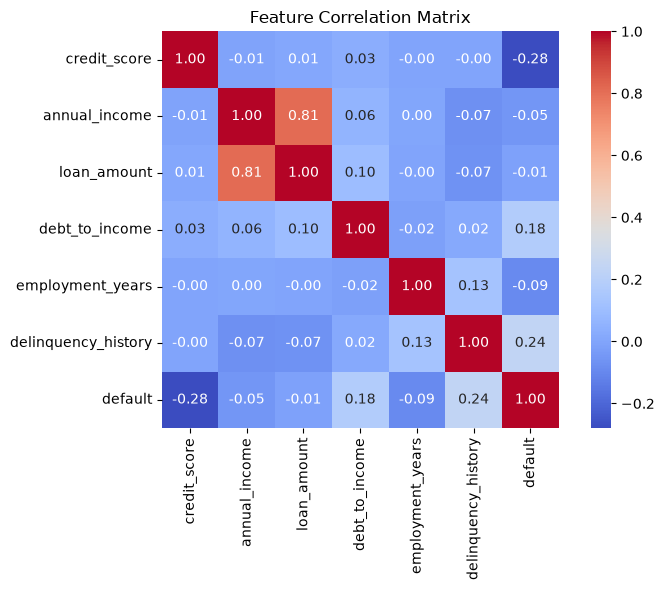

In [3]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Feature Correlation Matrix", fontsize=12)
plt.tight_layout()
plt.show()


In [4]:
# Feature definition and train/test split
features = ['credit_score', 'annual_income', 'loan_amount', 
            'debt_to_income', 'employment_years', 'delinquency_history']

X = df[features]
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")


Train samples: 400 | Test samples: 100


In [5]:
# Baseline Model: Single Decision Tree
tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

print("--- Single Decision Tree (max_depth=5) ---")
print(f"Accuracy:  {accuracy_score(y_test, tree_pred):.4f}")
print(f"Precision: {precision_score(y_test, tree_pred):.4f}")
print(f"Recall:    {recall_score(y_test, tree_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, tree_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, tree_prob):.4f}")


--- Single Decision Tree (max_depth=5) ---
Accuracy:  0.8000
Precision: 0.6000
Recall:    0.2727
F1-Score:  0.3750
ROC-AUC:   0.6442


In [6]:
# Ensemble Model: Random Forest Classifier (100 Trees)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, oob_score=True)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("--- Random Forest Classifier (100 Trees) ---")
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_prob):.4f}")
print(f"OOB Score: {rf_model.oob_score_:.4f}")


--- Random Forest Classifier (100 Trees) ---
Accuracy:  0.8200
Precision: 0.8333
Recall:    0.2273
F1-Score:  0.3571
ROC-AUC:   0.7255
OOB Score: 0.7850


In [7]:
# Comparison Table: Single Tree vs. Random Forest Ensemble
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Single Decision Tree": [
        accuracy_score(y_test, tree_pred),
        precision_score(y_test, tree_pred),
        recall_score(y_test, tree_pred),
        f1_score(y_test, tree_pred),
        roc_auc_score(y_test, tree_prob)
    ],
    "Random Forest Ensemble": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(results.round(4))


,Metric,Single Decision Tree,Random Forest Ensemble
0,Accuracy,0.8000,0.8200
1,Precision,0.6000,0.8333
2,Recall,0.2727,0.2273
3,F1-Score,0.3750,0.3571
4,ROC-AUC,0.6442,0.7255


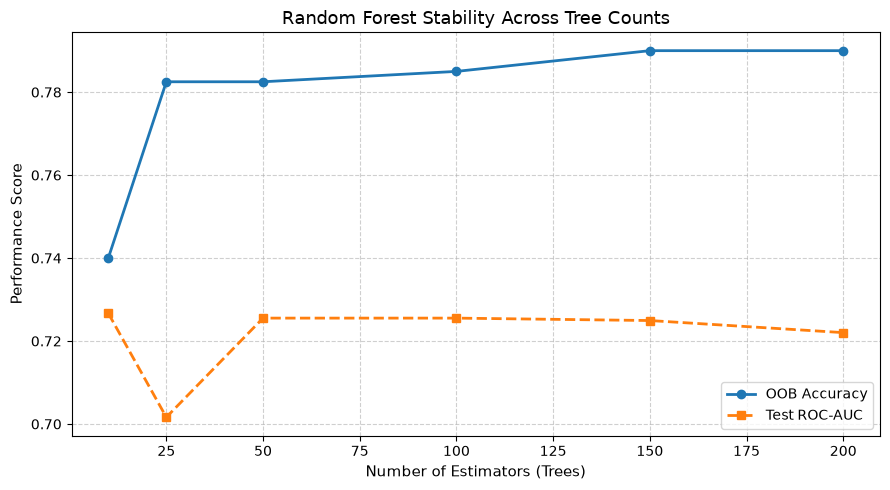

In [8]:
# Ensemble Size Sensitivity Analysis (Impact of n_estimators)
estimator_range = [10, 25, 50, 100, 150, 200]
oob_scores = []
test_scores = []

for n_trees in estimator_range:
    clf = RandomForestClassifier(n_estimators=n_trees, max_depth=6, oob_score=True, random_state=42)
    clf.fit(X_train, y_train)
    oob_scores.append(clf.oob_score_)
    test_scores.append(roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]))

plt.figure(figsize=(9, 5))
plt.plot(estimator_range, oob_scores, marker='o', label='OOB Accuracy', linewidth=2)
plt.plot(estimator_range, test_scores, marker='s', label='Test ROC-AUC', linewidth=2, linestyle='--')
plt.xlabel("Number of Estimators (Trees)", fontsize=11)
plt.ylabel("Performance Score", fontsize=11)
plt.title("Random Forest Stability Across Tree Counts", fontsize=13)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


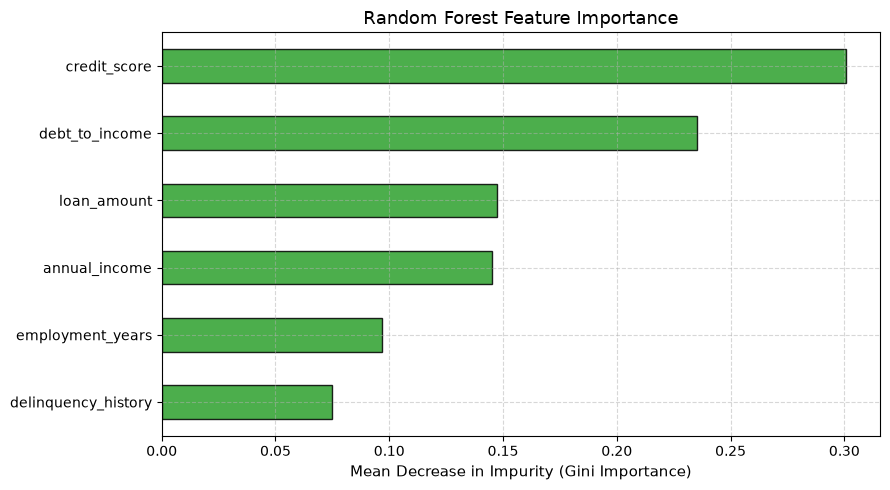

Feature Importance Values:
credit_score           0.3006
debt_to_income         0.2353
loan_amount            0.1475
annual_income          0.1450
employment_years       0.0968
delinquency_history    0.0747
dtype: float64


In [9]:
# Gini Feature Importance Ranking
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(9, 5))
importances.plot(kind='barh', color='#2ca02c', edgecolor='black', alpha=0.85)
plt.xlabel("Mean Decrease in Impurity (Gini Importance)", fontsize=11)
plt.title("Random Forest Feature Importance", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Feature Importance Values:")
print(importances.sort_values(ascending=False).round(4))


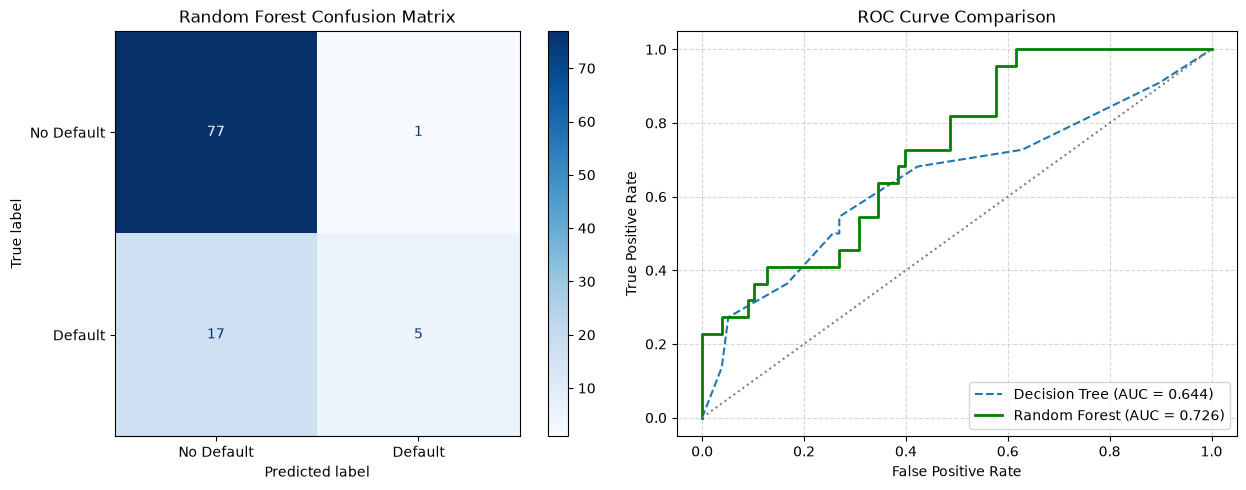

In [10]:
# Confusion Matrix & ROC Curve Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
disp.plot(cmap='Blues', ax=axes[0])
axes[0].set_title("Random Forest Confusion Matrix", fontsize=12)

# ROC Curve
fpr_tree, tpr_tree, _ = roc_curve(y_test, tree_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

axes[1].plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {roc_auc_score(y_test, tree_prob):.3f})', linestyle='--')
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})', linewidth=2, color='green')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve Comparison', fontsize=12)
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("confusion_and_roc.png", dpi=150)
plt.show()


In [11]:
# Inference on New Loan Applicant Profiles
# Profile 1: High Credit, Low Debt, Good Employment
# Profile 2: Borderline Credit, High Debt, Previous Delinquency
applicants = pd.DataFrame([
    [750, 85000, 25000, 18.5, 7, 0],
    [580, 42000, 22000, 46.2, 1, 1]
], columns=features, index=["Applicant A (Low Risk)", "Applicant B (High Risk)"])

preds = rf_model.predict(applicants)
probs = rf_model.predict_proba(applicants)

for idx, name in enumerate(applicants.index):
    verdict = "DEFAULT RISK (Declined)" if preds[idx] == 1 else "CREDIT APPROVED (Low Risk)"
    print(f"=== {name} ===")
    print(f"Decision: {verdict}")
    print(f"Default Probability: {probs[idx][1]:.2%}\n")


=== Applicant A (Low Risk) ===
Decision: CREDIT APPROVED (Low Risk)
Default Probability: 9.33%

=== Applicant B (High Risk) ===
Decision: DEFAULT RISK (Declined)
Default Probability: 76.29%

